# Benchmarking logical state-preparation circuits

Logical state preparation initializes the physical qubits of a code block in a chosen encoded state.
Faults in the preparation circuit can change that logical state, while flag measurements can identify some suspect shots for post-selection.

This notebook uses circuit-level simulation to evaluate three preparation workflows for the Steane code: a convenient non-fault-tolerant encoder, a flagged preparation circuit, and a Clifford proxy for a magic-state preparation circuit.
Each workflow is characterized by its estimated logical error rate; when post-selection is used, the discard rate is reported alongside it to show how often preparation must be repeated.

## Setup

Run the next cell once in a fresh notebook environment.
IPython's `%pip` magic installs into the active kernel, so the following imports use the same environment.

In [1]:
%%capture
%pip install qldpc matplotlib

In [2]:
import os
from collections.abc import Sequence

import matplotlib.pyplot as plt
import numpy as np
import numpy.typing as npt
import sinter
import stim
from matplotlib.figure import Figure

from qldpc import circuits, codes, decoders

NUM_WORKERS = max(1, min(4, (os.cpu_count() or 1) - 1))

In [3]:
def plot_sinter_results(
    stats: Sequence[sinter.TaskStats],
) -> tuple[Figure, npt.NDArray[np.object_]]:
    """Plot logical error rates and any discard rates in Sinter statistics."""
    with_discards = any(stat.discards for stat in stats)
    if with_discards:
        figure, axes = plt.subplots(1, 2, sharex=True, figsize=(7.5, 3.2))
        error_axis, discard_axis = axes
    else:
        figure, error_axis = plt.subplots(figsize=(4.5, 3.2))
        axes = np.array([error_axis])

    grouped = sinter.group_by(stats, key=lambda stat: stat.json_metadata.get("label", ""))
    markers = ("o", "s", "^", "D")
    for index, (label, group_stats) in enumerate(sorted(grouped.items())):
        plot_args = {
            "color": f"C{index}",
            "marker": markers[index % len(markers)],
            "label": label or "state preparation",
        }
        sinter.plot_error_rate(
            ax=error_axis,
            stats=group_stats,
            x_func=lambda stat: stat.json_metadata["p"],
            plot_args_func=lambda _index, _curve_id, _group, args=plot_args: args,
        )
        if with_discards and any(stat.discards for stat in group_stats):
            sinter.plot_discard_rate(
                ax=discard_axis,
                stats=group_stats,
                x_func=lambda stat: stat.json_metadata["p"],
                plot_args_func=lambda _index, _curve_id, _group, args=plot_args: args,
            )

    physical_rates = sorted({stat.json_metadata["p"] for stat in stats})
    error_axis.plot(
        physical_rates,
        physical_rates,
        color="black",
        linestyle=":",
        label=r"$p_{\mathrm{logical}}=p_{\mathrm{physical}}$",
    )
    error_axis.set_ylabel("estimated logical error rate")
    if with_discards:
        discard_axis.set_ylabel("estimated discard rate")

    for axis in axes:
        axis.set_xlabel("physical error rate per operation")
        axis.loglog()
        axis.grid(which="both", alpha=0.3)
        handles, labels = axis.get_legend_handles_labels()
        if handles:
            axis.legend(handles, labels, loc="best")
    figure.tight_layout()
    return figure, axes

## A non-fault-tolerant Steane encoder

`SinterDecoder` predicts logical-observable flips from detector events.
That differs from a code-capacity decoder, which predicts a physical correction from a parity-check syndrome.

`get_encoding_circuit` returns a convenient encoder, not a fault-tolerant one.
The sampled comparison below makes that limitation visible.

In [4]:
code = codes.SteaneCode()

# physical error rates to consider, and single-parameter family of noise models
error_rates = np.logspace(-3, -1, 5)
noise_model_family = circuits.DepolarizingNoiseModel

# use a lookup table decoder for these simulations
sinter_decoder = decoders.SinterDecoder(decoder=decoders.lookup(max_weight=1))

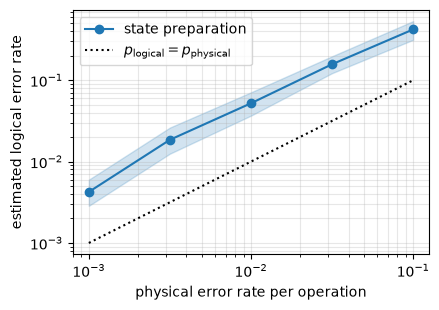

In [5]:
circuit = circuits.get_encoding_circuit(code)

# build sinter tasks to perform our simulations
tasks = circuits.get_state_prep_diagnostic_tasks(code, circuit, error_rates, noise_model_family)

# run simulations and collect statistics on error rates
stats = sinter.collect(
    tasks=tasks,
    decoders=["custom"],
    custom_decoders={"custom": sinter_decoder},
    num_workers=NUM_WORKERS,
    max_shots=100_000,
    max_errors=100,
)

# plot simulation results!
plot_sinter_results(stats)
plt.show()

At these sampled points, the encoder's estimated logical error rate sits above the physical operation rate.
That observation is about this circuit, noise model, decoder, and finite sample; it is not a statement about every Steane-code encoder.

## Flagged preparation and post-selection

A flagged preparation circuit measures ancillas that are designed to reveal dangerous faults.
Post-selection discards a shot when a selected flag detector fires.
The logical error rate is then computed only on the shots that remain, so it must be read together with the discard rate.

The circuit below follows the flagged Steane-state preparation in Figure 1c of [Goto (2016)](https://www.nature.com/articles/srep19578), also used in [arXiv:2603.04584](https://arxiv.org/abs/2603.04584).

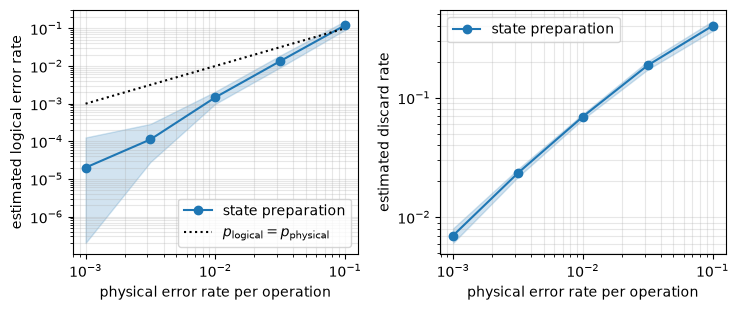

In [6]:
circuit = stim.Circuit("""
    # non-fault-tolerant state preparation
    H 0 2 4
    CX 0 3 2 1 4 5
    CX 0 1 2 6 4 3
    CX 2 5 3 6
    # flag errors in a logical Z representative
    H 7
    CZ 7 1 7 3 7 5
    MX 7
""")

# build sinter tasks to perform our simulations
tasks = circuits.get_state_prep_diagnostic_tasks(
    code,
    circuit,
    error_rates,
    noise_model_family,
    add_flags=True,
    post_select="flags",
)

# run simulations and collect statistics on error rates
stats = sinter.collect(
    tasks=tasks,
    decoders=["custom"],
    custom_decoders={"custom": sinter_decoder},
    num_workers=NUM_WORKERS,
    max_shots=100_000,
    max_errors=100,
)

# plot simulation results!
plot_sinter_results(stats)
plt.show()

The second panel is the cost of the lower conditional logical error rate.
A protocol with a small kept-shot error rate but an impractically large discard rate is not automatically better.

## A Clifford proxy for magic-state preparation

Stim cannot simulate the non-Clifford circuit in Figure 3b of [arXiv:2603.04584v1](https://arxiv.org/abs/2603.04584v1) directly.
Replacing the indicated $\pi/4$ rotations with Clifford $\pi/2$ rotations gives a proxy that prepares $|+\rangle$ instead of $|H\rangle$.

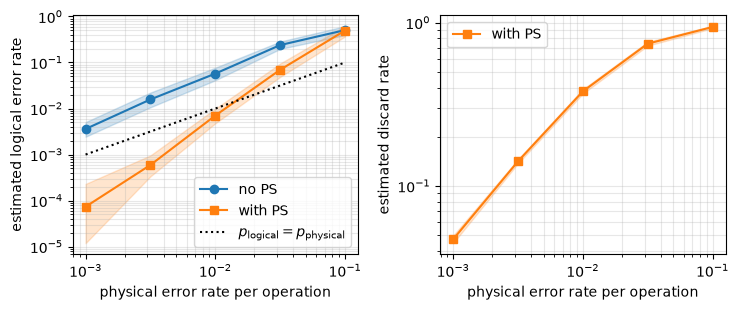

In [7]:
hadamard_prep_circuit = """
    H 1 2 3 7
    CX 1 0 3 5 7 6
    CX 1 4 2 6
    CX 2 0 1 5 3 6
    ########################################################
    TPP X1*X6  # "T-like" pi/4 rotation about a Pauli string
    ########################################################
    CX 7 6 6 4
    MX 7
    S_DAG 0 1 2 3 4 5 6  # logical S gate
    ##################################################################
    # logical stabilizer measurement
    H 8
    CX 8 9
    ###########################
    # controlled-Hadamard gates
    TPP_DAG Y0 Y1 Y2 Y3 Y4 Y5 Y6
    CZ 8 3 9 5
    CZ 8 0 9 2
    CZ 8 1 9 6
    CZ 8 4
    TPP Y0 Y1 Y2 Y3 Y4 Y5 Y6
    ###########################
    CX 8 9
    MX 8
    MZ 9
    ##################################################################
    # code stabilizer measurements
    H 11
    CX 3 10 11 2
    CX 2 10 11 3
    CX 1 10 11 4
    CX 4 10 11 1
    MZ 10
    MX 11
"""
circuit = stim.Circuit(hadamard_prep_circuit.replace("TPP", "SPP"))

# build sinter tasks to perform our simulations
tasks = circuits.get_state_prep_diagnostic_tasks(
    code, circuit, error_rates, noise_model_family, metadata=dict(label="no PS")
)
tasks += circuits.get_state_prep_diagnostic_tasks(
    code,
    circuit,
    error_rates,
    noise_model_family,
    add_flags=True,
    post_select="flags",
    metadata=dict(label="with PS"),
)

# run simulations and collect statistics on error rates
stats = sinter.collect(
    tasks=tasks,
    decoders=["custom"],
    custom_decoders={"custom": sinter_decoder},
    num_workers=NUM_WORKERS,
    max_shots=100_000,
    max_errors=100,
)

# plot simulation results!
plot_sinter_results(stats)
plt.show()

The two labelled curves use the same noisy proxy circuit with and without post-selection.

## One physical error rate

For a targeted check, `get_state_prep_diagnostic_circuit` provides an assembled Stim circuit and `get_logical_error_and_discard_rate` returns estimates at a single physical error rate.

In [8]:
diagnostic_circuit, _ = circuits.get_state_prep_diagnostic_circuit(code, circuit, add_flags=True)
noisy_diagnostic_circuit = noise_model_family(1e-3).noisy_circuit(diagnostic_circuit)
logical_error_rate, discard_rate = circuits.get_logical_error_and_discard_rate(
    noisy_diagnostic_circuit,
    sinter_decoder,
    num_samples=100_000,
    post_select=range(circuit.num_measurements),
)
print(logical_error_rate, discard_rate)

4.199386889514131e-05 0.04748
